# 3. Flow styles, classification, colours and projections

FlowMapper's three main flow styles, Tapered Fading Arc (**TAF**), Curve Half Arrow (**CHA**) and
Straight Half Arrow (**SHA**), with their shape options, classification methods, colour ramps,
projections and dark mode. Data: banana trade in South America (22 flows) and family-tree
migration between U.S. states, 1887–1924 (2,326 flows).

### Setup

Imports, the data folder, and a few helpers used below: `figure_ground()` (the high-contrast look),
`size_nodes_by_total_flow()`, `show()` / `map_image()` / `show_grid()` (draw maps) and
`compare_settings()` (draw the same map with different settings side by side).

In [1]:
%matplotlib inline
import io
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import flowmapper_org as fm

# Example data of the FlowMapper GitHub repository (folder "Data"): FLOWMAPPER_DATA, else the
# repository these notebooks live in (python/notebooks -> ../../Data), else a local clone.
_candidates = [os.environ.get("FLOWMAPPER_DATA"), Path.cwd().parent.parent / "Data", r"D:\GitHub\flowmapper\Data"]
DATA = next((Path(c) for c in _candidates if c and Path(c).is_dir()), None)
assert DATA is not None, ("FlowMapper example data not found: clone https://github.com/geo-social/flowmapper "
                          "and set FLOWMAPPER_DATA to its Data folder")
OUT = Path("output")
OUT.mkdir(exist_ok=True)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
print("flowmapper.org", fm.__version__, "- mirrors FlowMapper.org", fm.FLOWMAPPER_WEB_VERSION)

# ---------------------------------------------------------------------------------------------
# The look used in these notebooks: figure-ground contrast.
#   * flows are the figure: Tapered Fading Arc (TAF), dark colour ramps, full opacity;
#   * regions are the ground: their colours are kept but drawn pale (35 % opacity);
#   * nodes are drawn on top of the flows, dark grey with a white outline.
# figure_ground() only sets ordinary FlowMapper settings, so the projects still open on
# FlowMapper.org. CONTRAST holds two Python-only drawing options (never saved in the file):
#   flow_contrast - raises the opacity of the fading arcs, so small flows stay visible;
#   flow_halo     - a thin white casing that separates flows from the regions below.
# ---------------------------------------------------------------------------------------------
CONTRAST = dict(flow_contrast=0.5, flow_halo=("#ffffff", 0.7))

# Zoom extents (west, south, east, north), a drawing option: render(..., extent=...).
# The legend and title are kept outside the extent.
LOWER48 = (-125, 24, -66.5, 49.5)
EUROPE = (-12, 34, 58, 68)


def us_extent(p):
    """LOWER48 when most of the project's nodes are in the contiguous U.S., else None.

    Every U.S. map in these notebooks is zoomed to the lower 48 (not Alaska and Hawaii):
    map_image() / show() use this whenever no extent is given."""
    ns = p.node_settings
    xf, yf = ns.get("X"), ns.get("Y")
    if p.nodes is None or xf not in p.nodes.columns or yf not in p.nodes.columns:
        return None
    x = pd.to_numeric(p.nodes[xf], errors="coerce")
    y = pd.to_numeric(p.nodes[yf], errors="coerce")
    ok = x.notna() & y.notna()
    if not ok.any():
        return None
    w, s, e, n = LOWER48
    inside = (x[ok].between(w, e) & y[ok].between(s, n)).mean()
    return LOWER48 if inside >= 0.8 else None

# Dark ramps (light end, dark end). The light end is a mid-tone, so the smallest flows
# are still clearly visible; a ColorBrewer ramp such as "Blues" starts almost white.
FLOW_RAMPS = {
    "navy":   ("#4a6fa5", "#0b1f4b"),
    "orange": ("#f16913", "#7f2704"),
    "purple": ("#807dba", "#3f007d"),
    "teal":   ("#3a9e8f", "#00332b"),
}


def figure_ground(p, flows="navy", region_opacity=35, node_color="#3d3d3d"):
    """Pale regions, dark prominent flows, nodes on top (ordinary FlowMapper settings)."""
    lo, hi = FLOW_RAMPS[flows] if flows in FLOW_RAMPS else flows
    p.flow_settings.update(flowStyleName="TAF", clrScheme="Custom", minCustomColor=lo, maxCustomColor=hi,
                           fillOpacity=100)
    p.region_settings.update(fillOpacity=region_opacity, strokeColor="#9e9e9e", strokeWidth=0.4)
    p.node_settings.update(clrScheme="Custom", minCustomColor=node_color, maxCustomColor=node_color,
                           noAttrFillColor=node_color, strokeColor="#ffffff", strokeWidth=0.8, fillOpacity=100)
    p.view_settings["drawingOrder"] = "nodes"          # nodes on top of flows
    return p


def size_nodes_by_total_flow(p, rmin=2, rmax=16, title="Total flow (in + out)", measure="__fm:grossflow"):
    """Circle size = gross flow (in-flow + out-flow), calculated from the flows.

    measure="__fm:inflow" sizes by flow received instead: better when one origin sends
    everything (refugees from one country), where the origin's total would dwarf the rest."""
    p.node_settings.update(ifMapAttribute=True, volume=measure, cfMethod="Proportional",
                           radiusMin=rmin, radiusMax=rmax, legendTitle=title)
    return p


_seen_notices = set()


def map_image(project, contrast=True, **render_options):
    """Draw a project at its own size and return the picture as an array.

    contrast=True adds the CONTRAST drawing options; False draws exactly as FlowMapper.org.
    Legends, title and scale bar are sized in screen pixels, so maps are drawn on their own
    and then tiled, rather than squeezed into small subplot axes."""
    opts = {**(CONTRAST if contrast else {}), **render_options}
    if "extent" not in opts and us_extent(project) is not None:
        opts["extent"] = LOWER48         # U.S. data: the lower 48, never Alaska and Hawaii
    r = project.render(**opts)       # with an extent, the title and legend are kept off the extent
    for n in r.notices:                     # FlowMapper's messages, each shown once
        if n not in _seen_notices:
            _seen_notices.add(n)
            print("notice:", n)
    buf = io.BytesIO()
    r.fig.savefig(buf, format="png")
    buf.seek(0)
    return plt.imread(buf)


def show(project, width=1000, height=700, contrast=True, **render_options):
    """Draw one map in the notebook."""
    show_grid([map_image(project, contrast, width=width, height=height, **render_options)], ncols=1,
              width=width / 70)


def show_grid(images, titles=None, ncols=3, width=22):
    """Tile pictures (arrays from map_image or plt.imread) in a grid."""
    nrows = -(-len(images) // ncols)
    h, w = images[0].shape[:2]
    fig, axes = plt.subplots(nrows, ncols, figsize=(width, width / ncols * h / w * nrows + 0.4 * nrows), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, im, t in zip(axes.flat, images, titles or [""] * len(images)):
        ax.imshow(im)
        ax.set_title(t)
    plt.tight_layout()
    plt.show()


def compare_settings(base, variants, ncols=3, width=900, height=600, **render_options):
    """Draw copies of `base`, each with some settings changed.

    variants = {"label": {"flow_settings": {...}, "node_settings": {...}, ...}, ...}"""
    images = []
    for label, change in variants.items():
        q = base.copy()
        for block, values in change.items():
            getattr(q, block).update(values)
        images.append(map_image(q, width=width, height=height, **render_options))
    show_grid(images, list(variants), ncols=ncols)

flowmapper.org 0.3.0 - mirrors FlowMapper.org 2.1


In [2]:
bananas = fm.Project.load(DATA / "Bananas" / "flowmapper_bananas_SA_2019.json")
figure_ground(bananas, flows="navy")
bananas.flow_settings.update(widthMin=2, widthMax=14)

family = fm.Project.load(DATA / "FamilyTree" / "flowmapper_1887_1924.json")
figure_ground(family, flows="purple")
family.flow_settings.update(numTopFlows=150, legendTitle="Migrants 1887-1924")

from flowmapper_org.geometry import FLOW_STYLE_ALIASES
{k: v for k, v in FLOW_STYLE_ALIASES.items() if k in ("TAF", "CHA", "SHA")}

{'TAF': 'nyt', 'CHA': 'curve', 'SHA': 'strtHfArw'}

## The three flow styles

`flowStyleName` accepts the short names `"TAF"`, `"CHA"`, `"SHA"` (or the labels). The project
file stores FlowMapper's values (`"nyt"`, `"curve"`, `"strtHfArw"`).

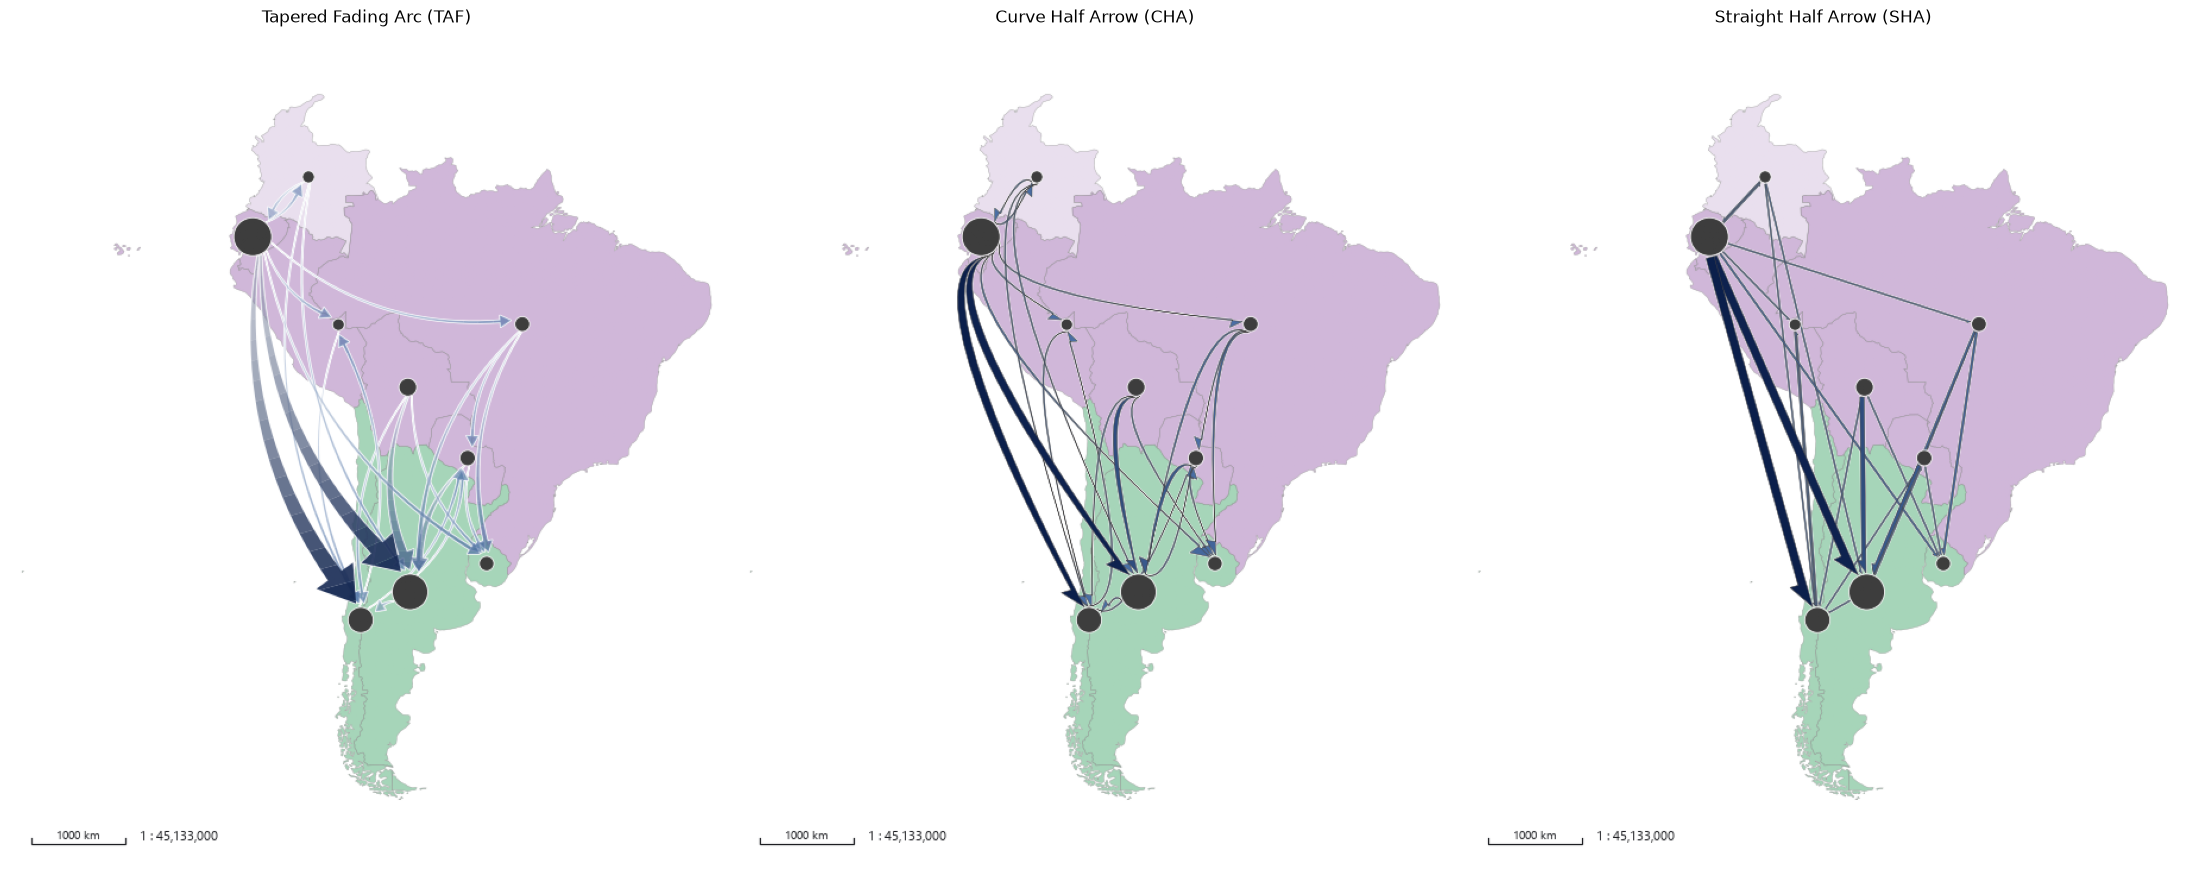

notice: 154 flows use node IDs that are not in the node file (or have no coordinates), e.g. 143, 102, 108, 115, 149, .... They are not drawn.


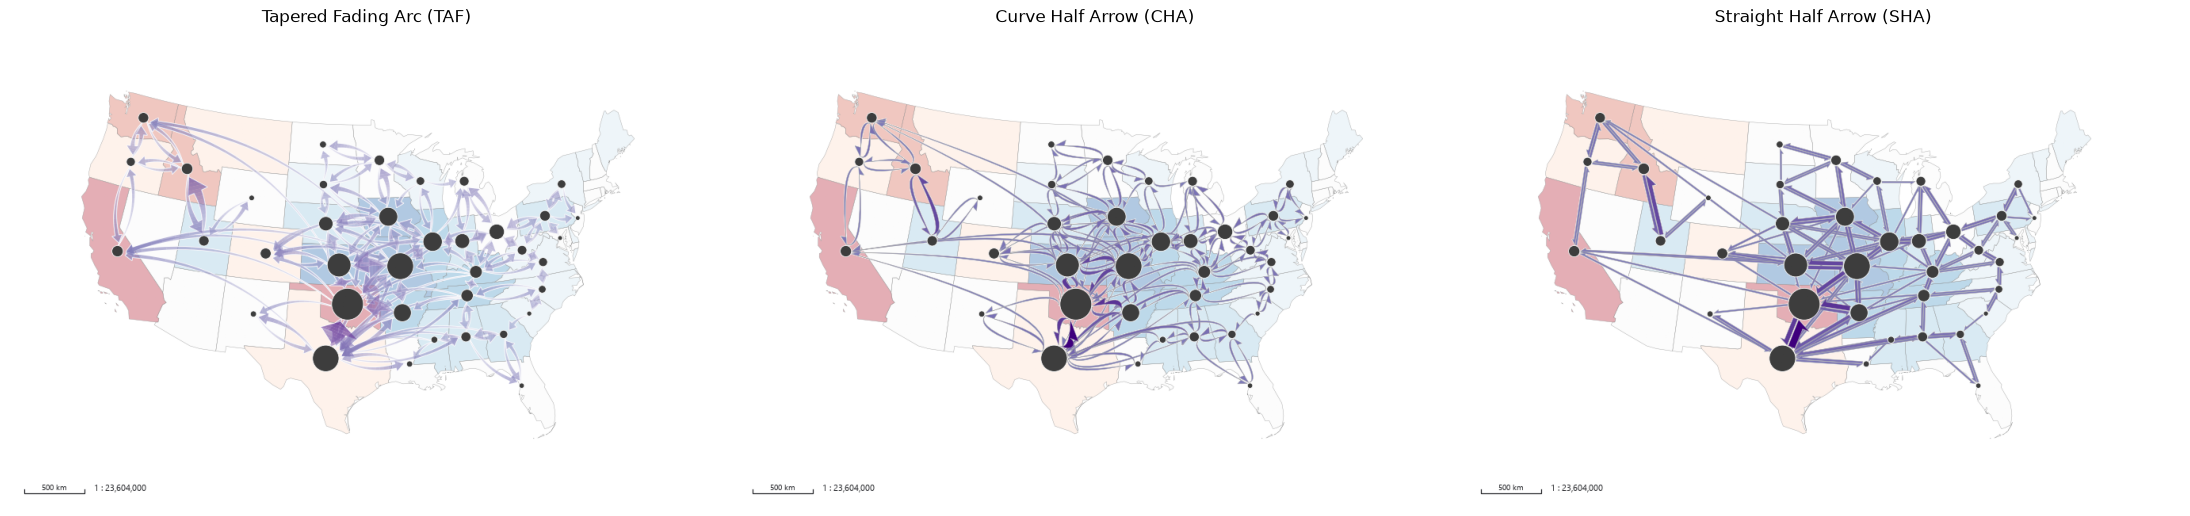

In [3]:
styles = {"TAF": "Tapered Fading Arc", "CHA": "Curve Half Arrow", "SHA": "Straight Half Arrow"}
compare_settings(bananas, {f"{label} ({k})": {"flow_settings": {"flowStyleName": k}} for k, label in styles.items()},
                 width=600, height=700, legend=False)
compare_settings(family, {f"{label} ({k})": {"flow_settings": {"flowStyleName": k}} for k, label in styles.items()},
                 legend=False)

## Shape: curvature, bend, arrow heads, bundling

`symbology` holds the shape sliders of the Flows tab. Change one entry, keep the rest.

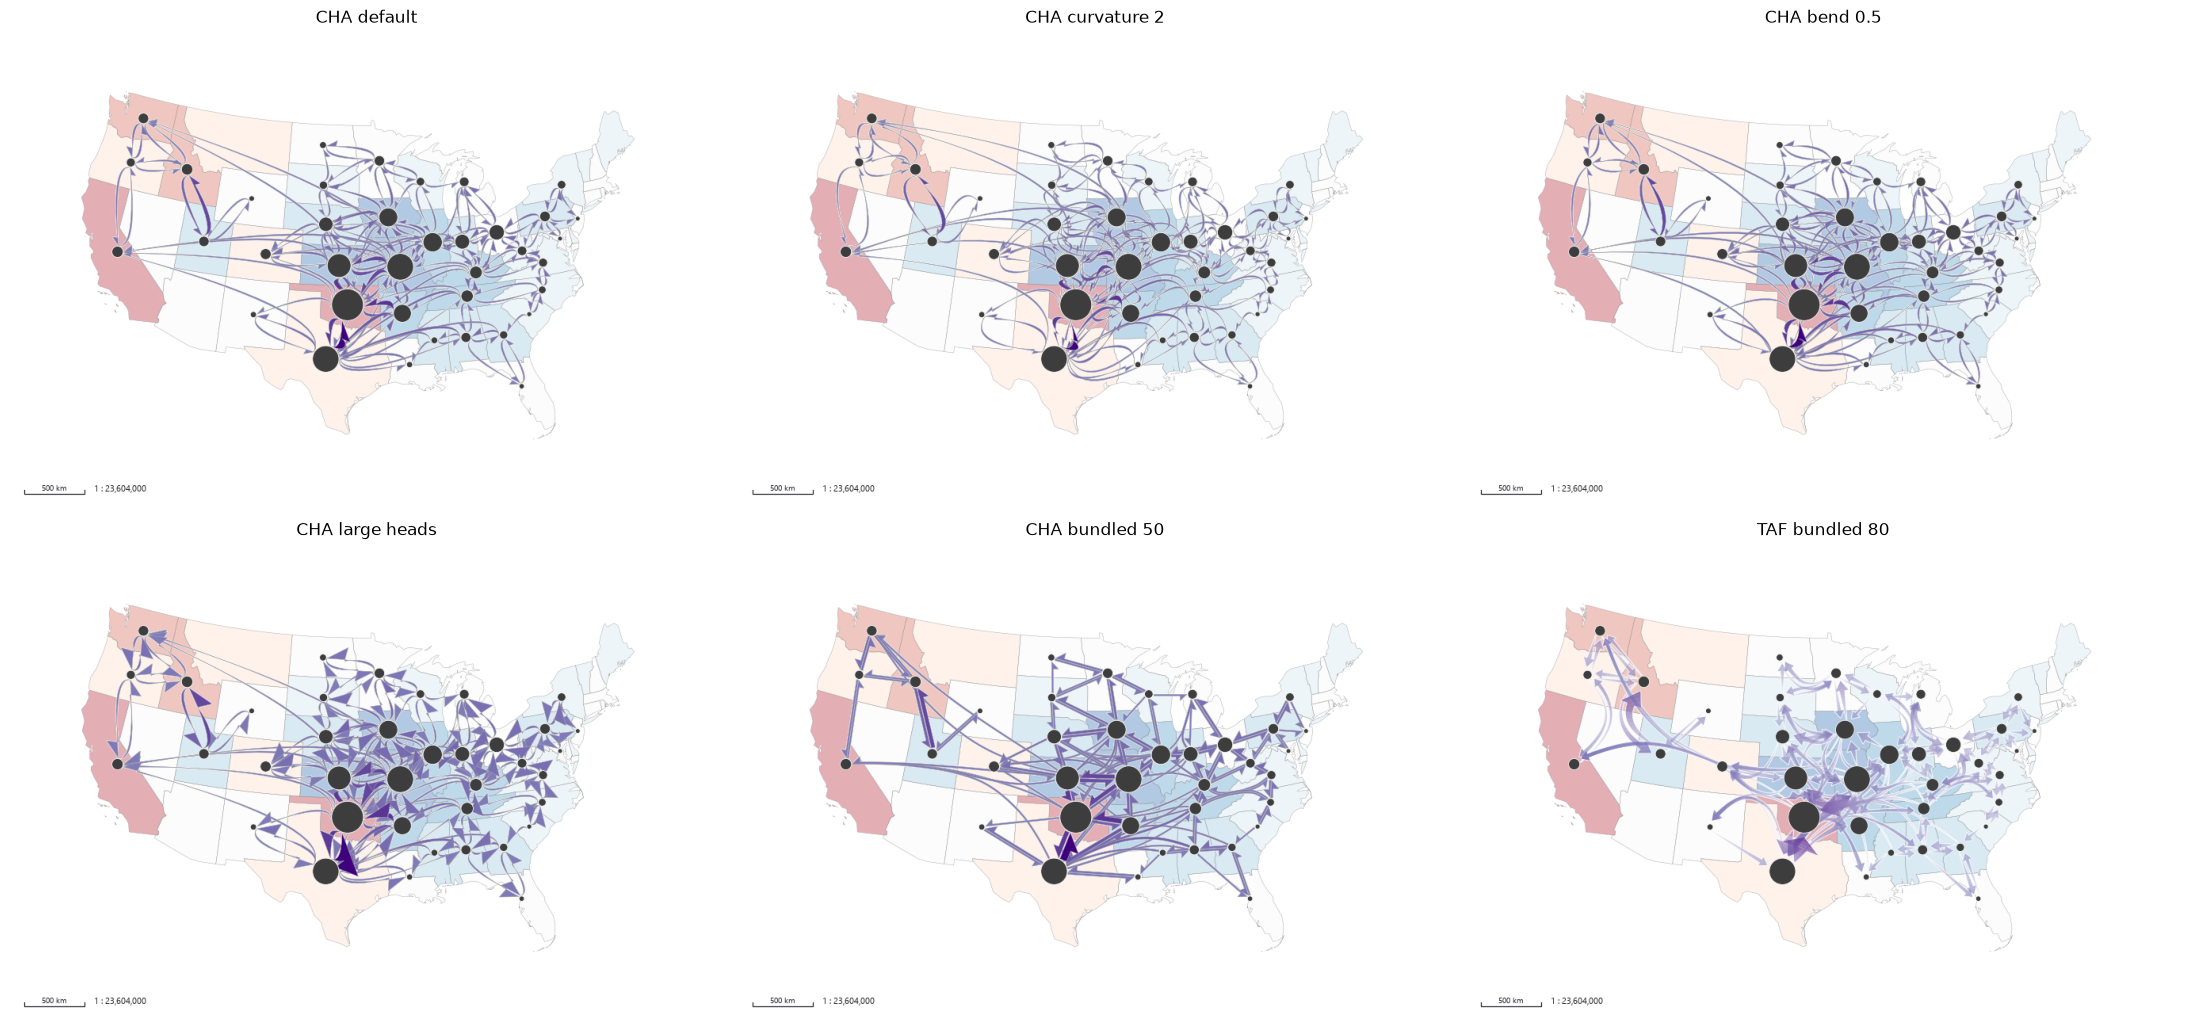

In [4]:
sym = family.flow_settings["symbology"]
variants = {
    "CHA default": {},
    "CHA curvature 2": {"curvature": 2},
    "CHA bend 0.5": {"bend": 0.5},
    "CHA large heads": {"headLength": 2, "headWidth": 2},
    "CHA bundled 50": {"bundle": True, "bundleStrength": 50},
    "TAF bundled 80": {"bundle": True, "bundleStrength": 80},
}
compare_settings(family, {label: {"flow_settings": {"flowStyleName": "TAF" if label.startswith("TAF") else "CHA",
                                                    "symbology": {**sym, **change}}}
                          for label, change in variants.items()}, legend=False)

## Classification methods

`fm.classify_values` is FlowMapper's classification (the same breaks as the web site, checked by
the parity tests).

In [5]:
vols = family.flows[family.flow_settings["volume"]]
rows = []
for method, kw in [("Quantile", {}), ("EqualInterval", {}), ("NaturalBreak", {}),
                   ("ManualBreak", {"breaks": "1 100 250 500 1000 8000"})]:
    c = fm.classify_values(vols, method, 5, **kw)
    counts = pd.Series(c.classes).value_counts().sort_index()
    rows.append({"method": method,
                 "classes": ",  ".join(f"{lo:g}–{hi:g}" for lo, hi in c.bounds),
                 "flows per class": counts.tolist()})
pd.DataFrame(rows)

,method,classes,flows per class
0,Quantile,"0–0, 0–5, 5–27, 27–90, 90–7790","[869, 526, 462, 469]"
1,EqualInterval,"0–1558, 1558–3116, 3116–4674, 4674–6232, 6...","[2307, 12, 5, 1, 1]"
2,NaturalBreak,"0–263, 263–949, 949–3022, 3022–7790, 7790–...","[2095, 175, 48, 7, 1]"
3,ManualBreak,"0–100, 100–250, 250–500, 500–1000, 1000–8000","[1887, 202, 113, 72, 52]"


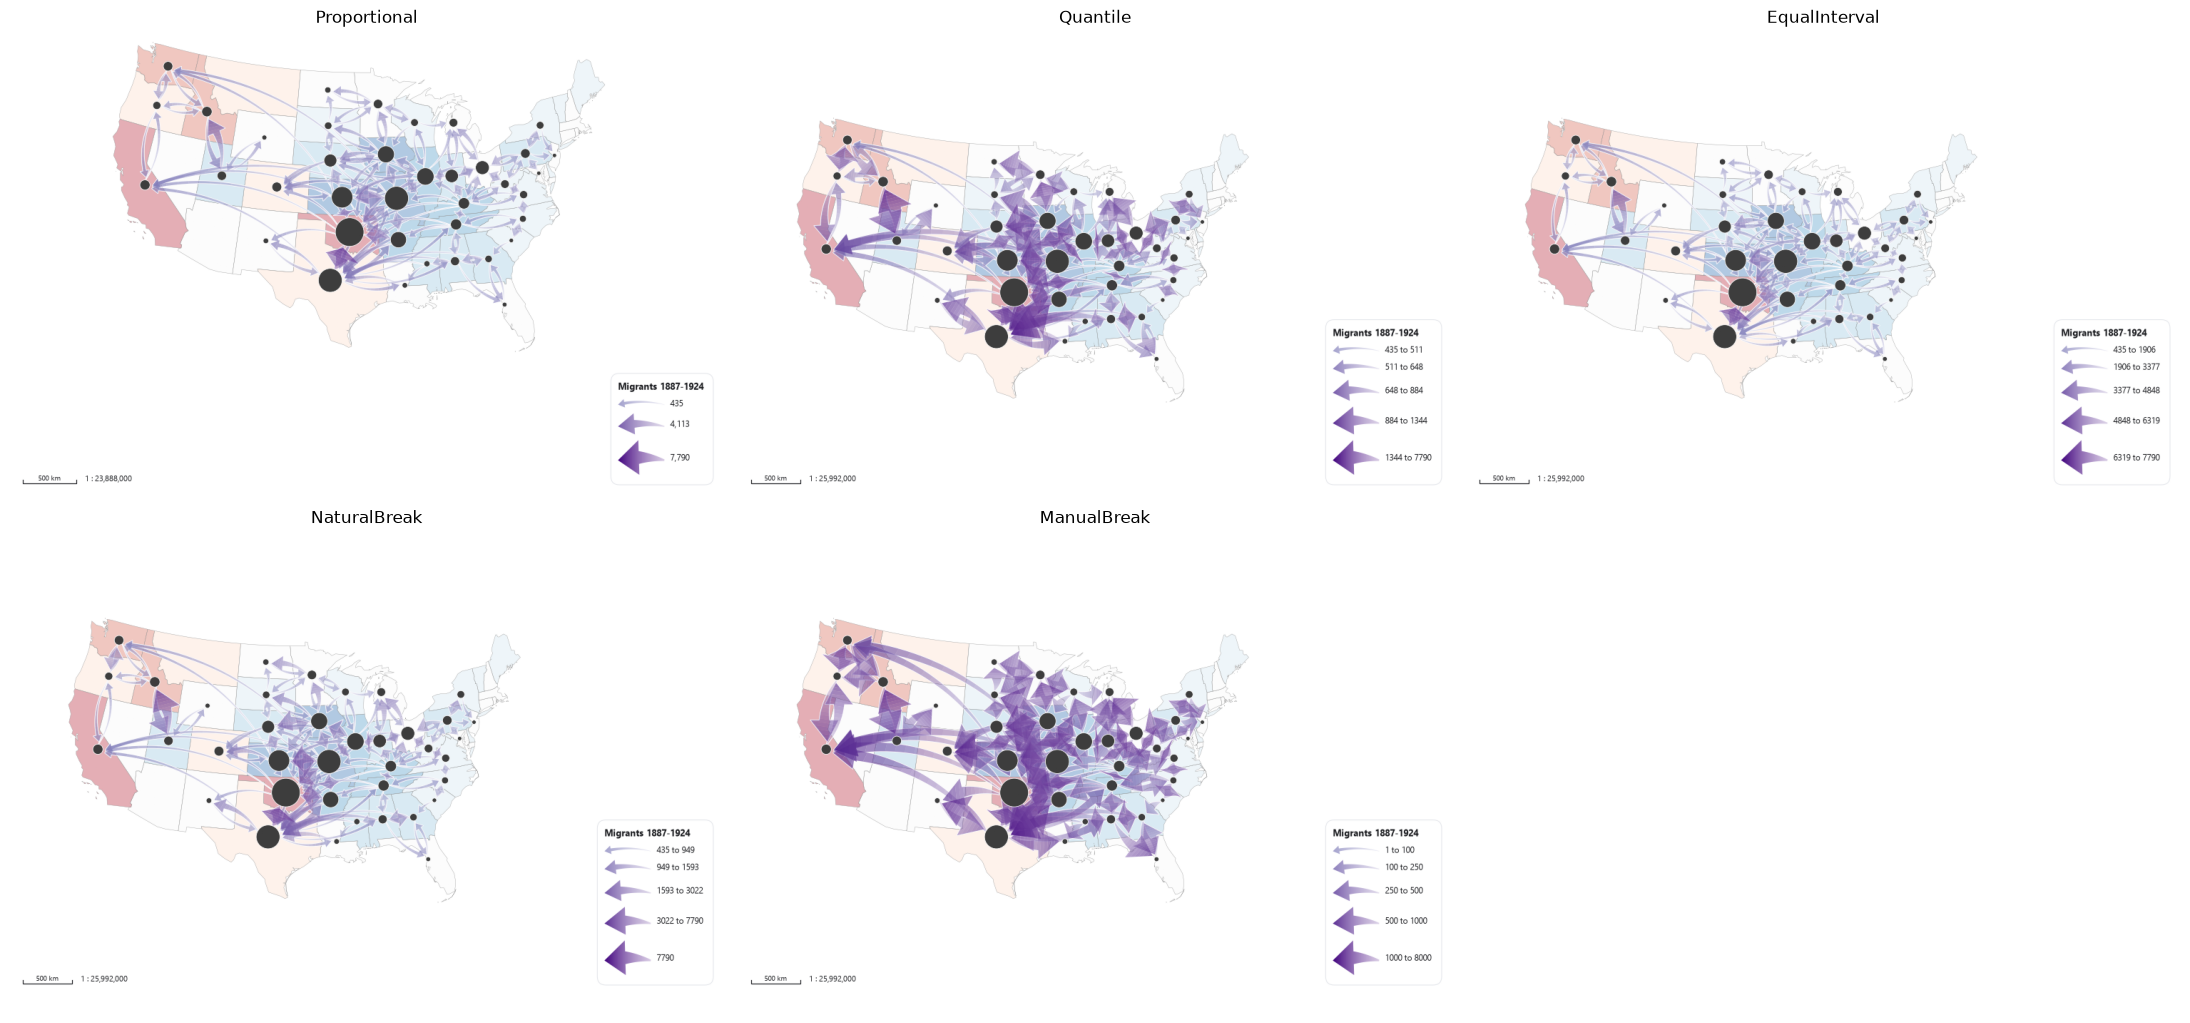

In [6]:
compare_settings(family, {
    "Proportional": {"flow_settings": {"cfMethod": "Proportional"}},
    "Quantile": {"flow_settings": {"cfMethod": "Quantile"}},
    "EqualInterval": {"flow_settings": {"cfMethod": "EqualInterval"}},
    "NaturalBreak": {"flow_settings": {"cfMethod": "NaturalBreak"}},
    "ManualBreak": {"flow_settings": {"cfMethod": "ManualBreak", "breakInput": "1 100 250 500 1000 8000"}},
}, width=1000, height=650, legend={"flows": True, "nodes": False, "regions": False})

## Colours that stand out

Dark ramps whose light end is a mid-tone (`FLOW_RAMPS` in the setup cell) keep small flows
visible. A ColorBrewer ramp such as `"Blues"` starts almost white, so its smallest class fades
into the background. Pick a flow hue that differs from the regions' hue: these regions are
red/blue, so purple, orange or teal flows separate best.

sequential: ['Blues', 'Greens', 'Greys', 'Oranges', 'Purples', 'Reds', 'BuGn', 'BuPu', 'GnBu', 'OrRd', 'PuBu', 'PuBuGn', 'PuRd', 'RdPu', 'YlGn', 'YlGnBu', 'YlOrBr', 'YlOrRd']


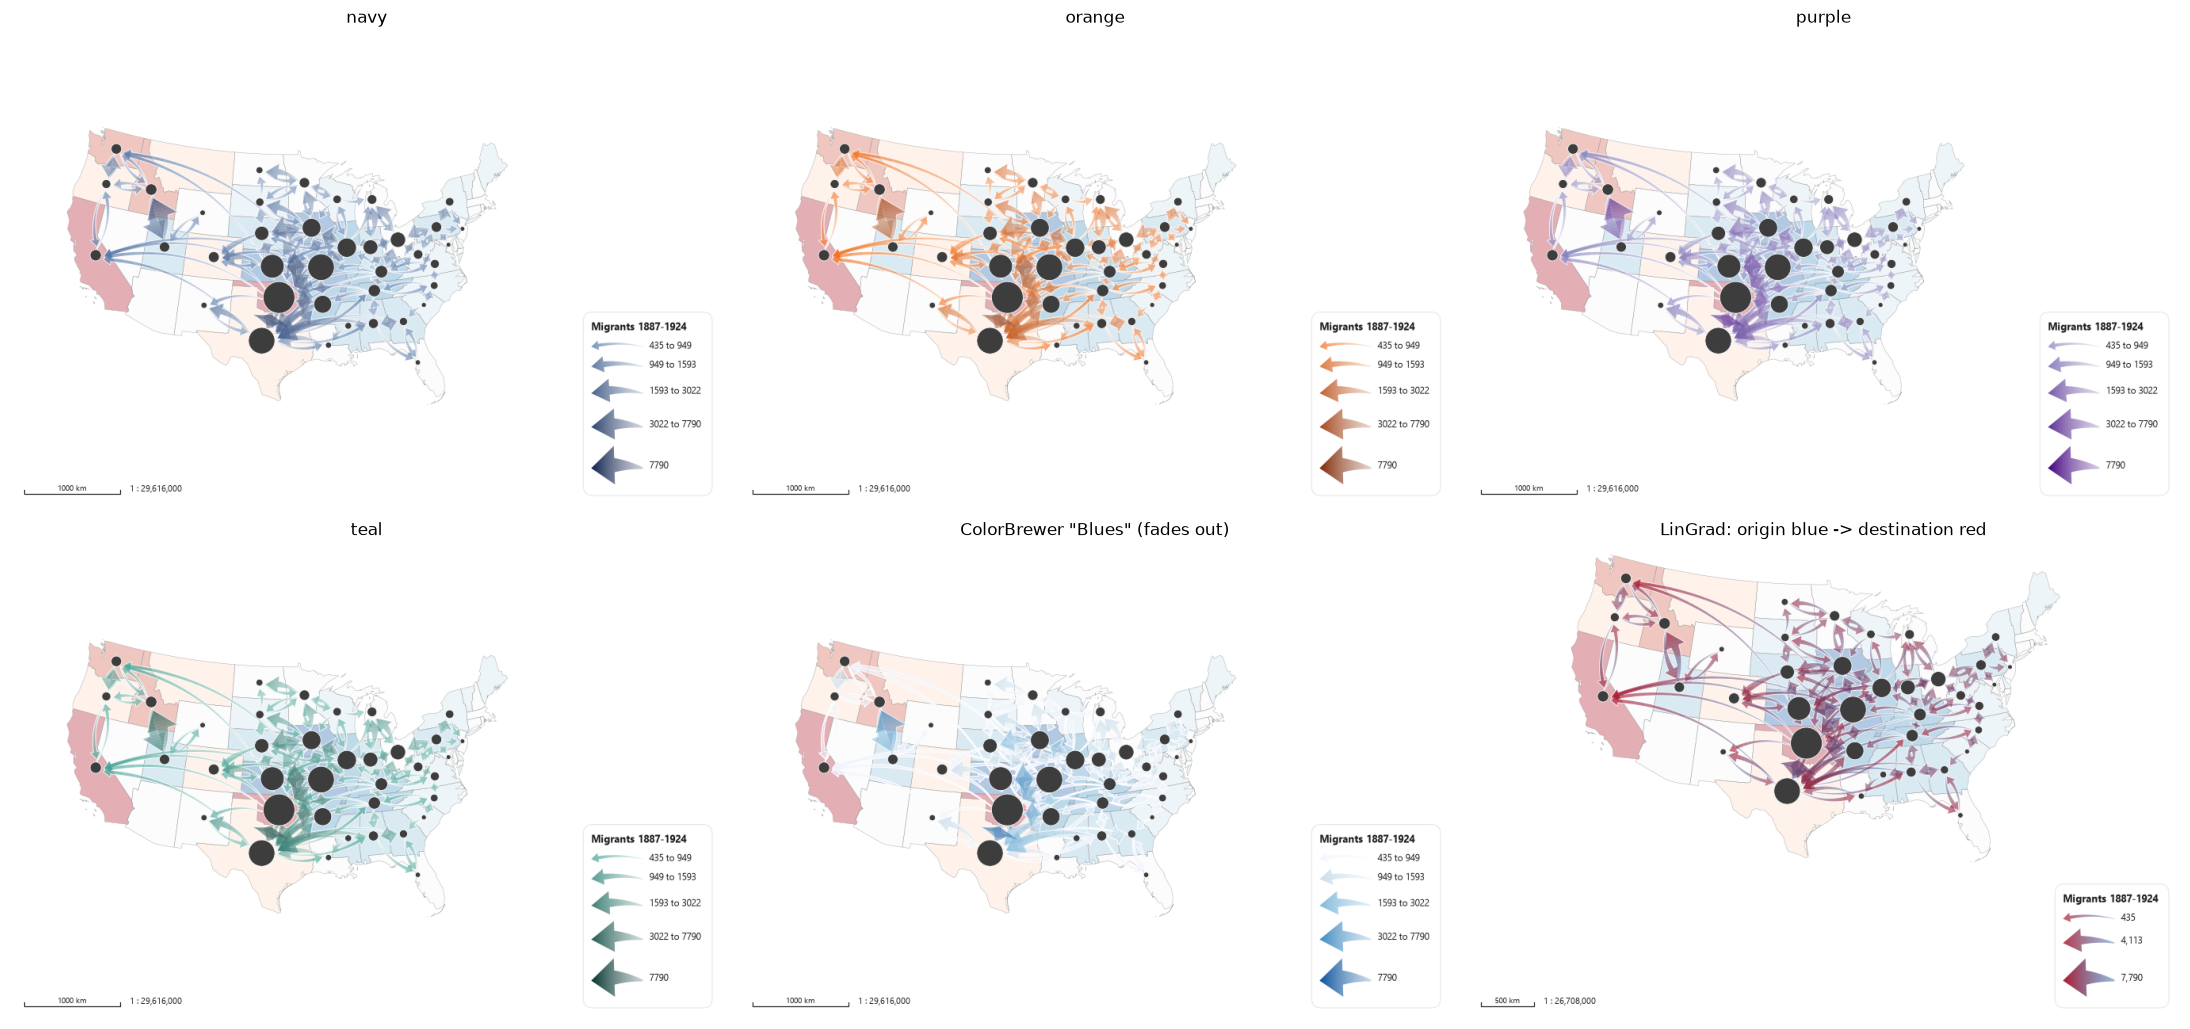

In [7]:
from flowmapper_org.colors import SCHEME_CATALOG
print("sequential:", [s for s, _ in SCHEME_CATALOG["sequential"]])
ramps = {name: {"flow_settings": {"clrScheme": "Custom", "minCustomColor": lo, "maxCustomColor": hi,
                                  "cfMethod": "NaturalBreak"}} for name, (lo, hi) in FLOW_RAMPS.items()}
ramps['ColorBrewer "Blues" (fades out)'] = {"flow_settings": {"clrScheme": "Blues", "cfMethod": "NaturalBreak"}}
ramps["LinGrad: origin blue -> destination red"] = {"flow_settings": {"clrScheme": "LinGrad",
    "originColor": "#2166ac", "destinationColor": "#b2182b"}}
compare_settings(family, ramps, legend={"flows": True, "nodes": False, "regions": False})

## Projections

{'North America': ['abEqAreaUS', 'laeaNA', 'lccCanada', 'abEqAreaAk'], 'Europe and Middle East': ['abEqAreaEu', 'laeaEurope', 'ukBNG', 'lccTurkey', 'abEqAreaME', 'abEqAreaRu'], 'Asia, Africa, Oceania, S. America': ['abEqAreaCn', 'abEqAreaIn', 'abEqAreaAfc', 'abEqAreaAs', 'abEqAreaSthAm'], 'Polar': ['laeaArctic', 'psAntarctic'], 'World': ['eqEarth', 'robin', 'moll', 'gall', 'webMct']}


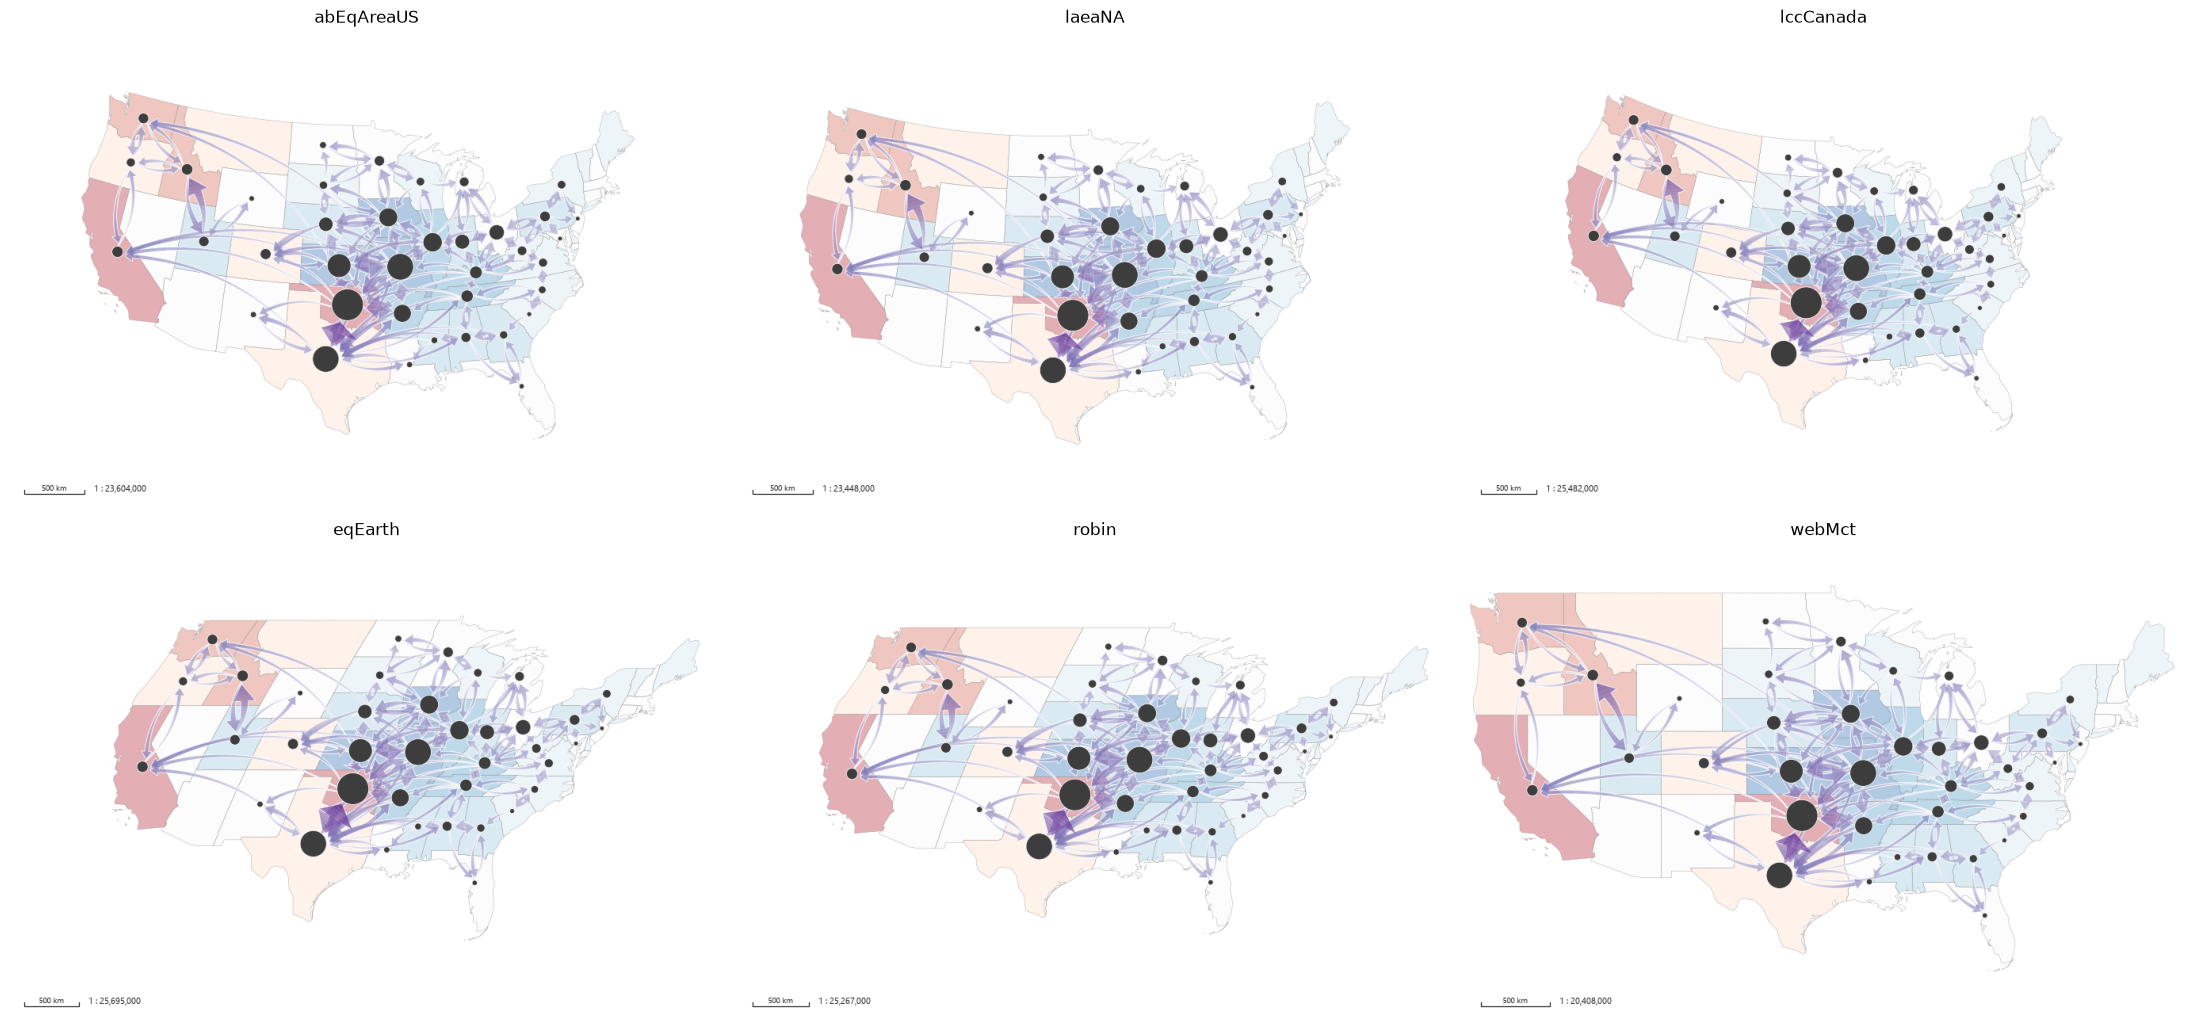

In [8]:
from flowmapper_org.projections import PROJECTION_GROUPS
print(PROJECTION_GROUPS)
prjs = ["abEqAreaUS", "laeaNA", "lccCanada", "eqEarth", "robin", "webMct"]
show_grid([map_image(family, width=900, height=600, projection=p, legend=False) for p in prjs], prjs, ncols=3)

## Dark mode, north arrow, projection label

On a dark background the halo takes the background colour; light flow colours give the contrast.

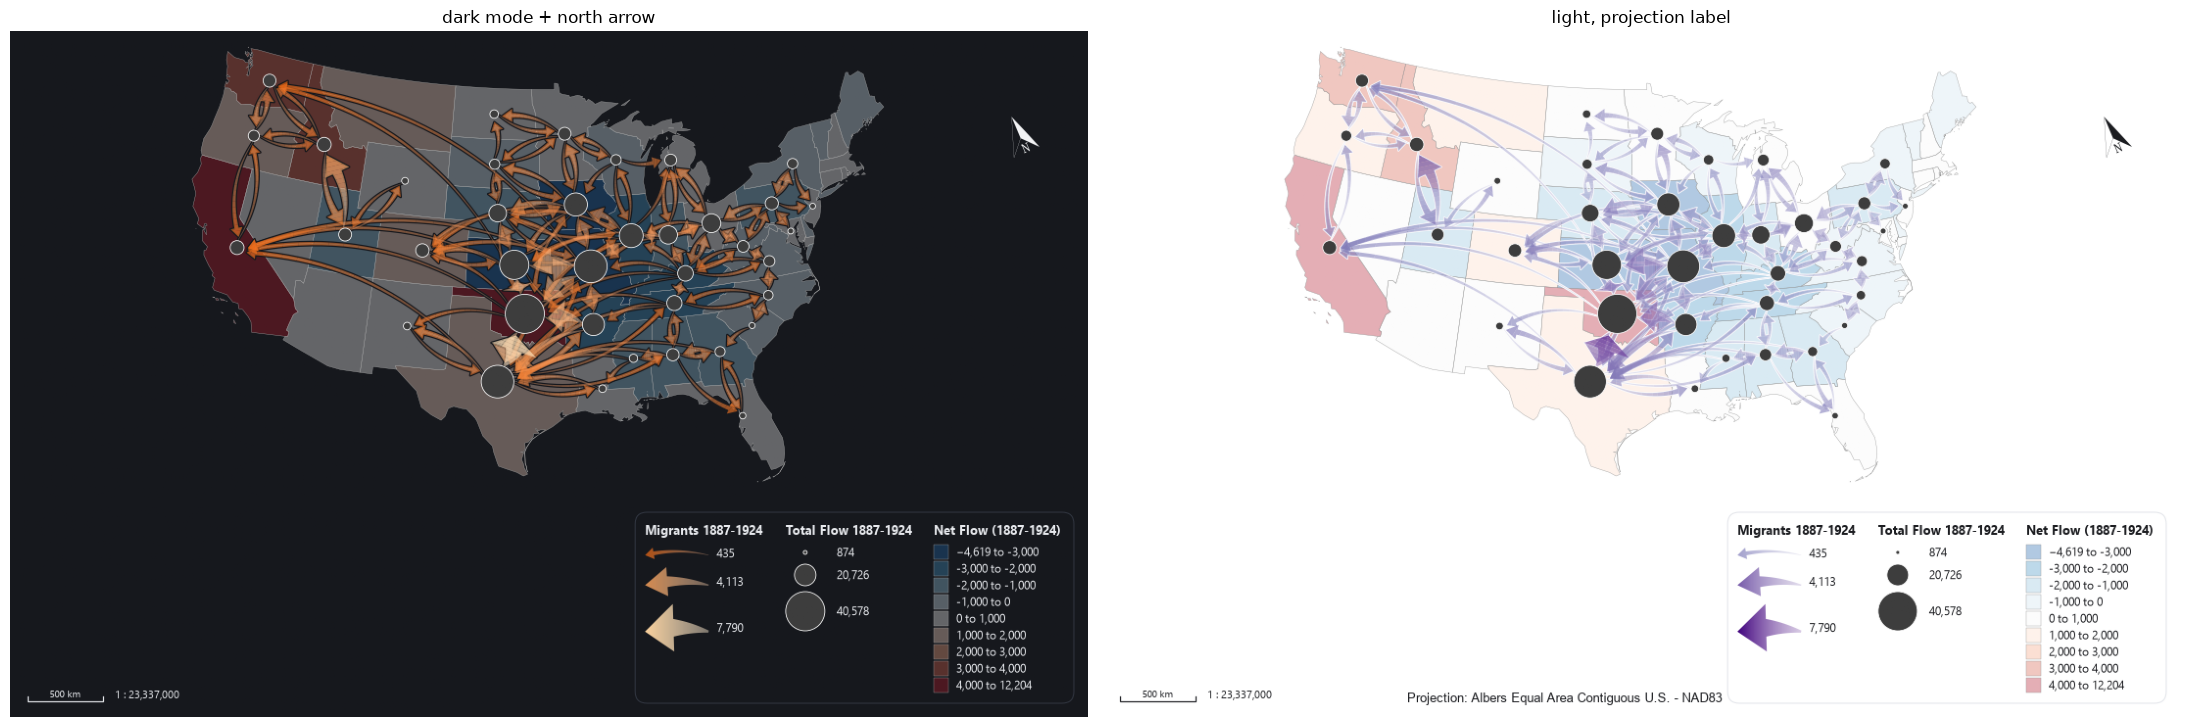

In [9]:
dark = family.copy()
dark.flow_settings.update(clrScheme="Custom", minCustomColor="#f16913", maxCustomColor="#fdd49e")
show_grid([map_image(dark, width=1100, height=700, dark=True, north_arrow=True, flow_halo=True),
           map_image(family, width=1100, height=700, projection_label=True, north_arrow=True)],
          ["dark mode + north arrow", "light, projection label"], ncols=2)